# **실습 개요**

여러분은 한 교육 컨설팅 회사의 데이터 분석팀에 합류했습니다. <br>
이 회사는 학생들의 학습 습관 데이터를 바탕으로
최종 학업 성취도(Performance Index)를 예측하는 모델을 만들어,<br>학생들에게 맞춤형 학습 전략을 제안하려고 합니다.

## **데이터셋 설명**

학생들의 학습 습관과 최종 학업 성취도(Performance Index)에 대한 데이터입니다.

| 컬럼명 | 설명 |
|---|---|
| Hours Studied | 하루 평균 학습 시간 (시간) |
| Previous Scores | 이전 시험 점수 (0~100) |
| Extracurricular Activities | 과외활동 참여 여부 (Yes/No) |
| Sleep Hours | 하루 평균 수면 시간 (시간) |
| Sample Question Papers Practiced | 풀어본 모의고사(기출문제) 수 |
| Weekly Study Hours | 주간 총 학습 시간 (시간) |
| Performance Index | **[target]** 최종 학업 성취도 지수 (0~100, 값이 클수록 우수) |

## **데이터셋 URL**
url : https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/student_performance.csv


## **1. 데이터 살펴보기**

데이터를 불러오고, 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/student_performance.csv")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Weekly Study Hours,Performance Index
0,6,92.0,Yes,9.0,4.0,42.2,86
1,1,54.0,No,7.0,7.0,6.9,28
2,7,45.0,Yes,6.0,6.0,49.3,38
3,5,70.0,Yes,4.0,6.0,35.6,55
4,1,47.0,Yes,5.0,0.0,6.9,18


**Q1. 데이터의 shape(행, 열 개수)을 확인하세요.**

In [4]:
# code here
df.shape

(1200, 7)

**Q2. 각 컬럼의 기본적인 정보를 확인하세요.**

In [ ]:
# code here
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 7 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   Hours Studied                     1200 non-null   int64  
 1   Previous Scores                   1164 non-null   float64
 2   Extracurricular Activities        1200 non-null   str    
 3   Sleep Hours                       1116 non-null   float64
 4   Sample Question Papers Practiced  1140 non-null   float64
 5   Weekly Study Hours                1200 non-null   float64
 6   Performance Index                 1200 non-null   int64  
dtypes: float64(4), int64(2), str(1)
memory usage: 65.8 KB


**Q3. 수치형 컬럼들의 통계 요약을 확인하세요.**

In [6]:
# code here
df.describe()

,Hours Studied,Previous Scores,Sleep Hours,Sample Question Papers Practiced,Weekly Study Hours,Performance Index
count,1200.000000,1164.000000,1116.000000,1140.000000,1200.000000,1200.000000
mean,5.150000,68.880584,6.419355,4.497368,36.065417,54.829167
std,2.965326,17.195262,1.686066,2.910577,20.754526,19.941616
min,1.000000,40.000000,4.000000,0.000000,6.200000,-12.000000
25%,3.000000,54.000000,5.000000,2.000000,20.800000,40.000000
50%,5.000000,68.000000,6.000000,5.000000,35.100000,54.000000
75%,7.000000,83.250000,8.000000,7.000000,49.200000,70.000000
max,25.000000,99.000000,9.000000,9.000000,175.000000,130.000000


## **2. 데이터 분석하기**

데이터를 분석하여 인사이트를 찾아내는 과정입니다.
- 각 컬럼이 어떤 의미를 갖는지, 데이터의 전체적인 형태가 어떤지 살펴봅니다.
- 그리고 데이터를 이해하기 위한 여러 정보들을 찾아 csv 형태로 추출하여 채점 사이트에 제출합니다.

colab에서 csv 파일 다운로드하기
```
from google.colab import files
files.download("submission.csv")
```

### **2-1. 데이터 탐색**

**Q1. 데이터를 분석하여 다음 정보를 찾아 주세요.**

Extracurricular Activities 여부에 따른 Performance Index의 평균을 소수점 2자리까지 구하시오.

In [50]:
# code here
# q1_1 = df[df["Extracurricular Activities"] == "No"]["Performance Index"].mean().round(2)
# q1_2 = df[df["Extracurricular Activities"] == "Yes"]["Performance Index"].mean().round(2)
# pd.DataFrame([q1_1, q1_2], columns = ["Performance Index"]).to_csv("Test01.csv", index=False)
pd.DataFrame(df.groupby("Extracurricular Activities")["Performance Index"].mean().round(2), columns=["Performance Index"]).to_csv("Test01.csv")
# print(f"No일 때의 평균: {df[df["Extracurricular Activities"] == "No"]["Performance Index"].mean().round(2)}")
# print(f"Yes일 때의 평균: {df[df["Extracurricular Activities"] == "Yes"]["Performance Index"].mean().round(2)}")

**Q2. 데이터를 분석하여 다음 정보를 찾아 주세요.**

- 학습 시간 기준 상위 10명의 평균 Performance Index를 소수점 2자리까지 확인하세요.
- 수면 시간이 6시간 미만인 학생들의 평균 Performance Index를 소수점 2자리까지 확인하세요.
- Performance Index가 0보다 작거나 100보다 큰(상식적으로 불가능한) 행이 몇 개인지 확인하세요.

각 값을 "ans" 열에 순서대로 저장하여 제출합니다.

In [28]:
# code here
q2_1 = df.sort_values("Hours Studied", ascending=False).head(10)["Performance Index"].mean().round(2)
q2_2 = df[df["Sleep Hours"] < 6]["Performance Index"].mean().round(2)
q2_3 = len(df[(df["Performance Index"] < 0) | (df["Performance Index"] > 100)])

pd.DataFrame([q2_1, q2_2, q2_3], columns=["ans"]).to_csv("Test02.csv", index=False)


**Q5. 데이터를 분석하여 다음 정보를 찾아 주세요.**
- Extracurricular Activities 여부에 따른 풀어본 문제집 수의 평균과 중앙값을 함께 비교하세요.
- 두 값 모두 소수점 2자리까지로 정리해 주세요.

In [43]:
# code here
# q3_1 = df[df["Extracurricular Activities"] == "No"]["Sample Question Papers Practiced"].agg(["mean", "median"]).round(2)
# q3_2 = df[df["Extracurricular Activities"] == "Yes"]["Sample Question Papers Practiced"].agg(["mean", "median"]).round(2)

sub = df.groupby("Extracurricular Activities")["Sample Question Papers Practiced"].agg(["mean", "median"]).round(2)
sub.to_csv("Test03.csv")

### **2-2. 데이터 시각화**

**Q1. Performance Index의 분포를 히스토그램으로 시각화하세요.**

그리고 이 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

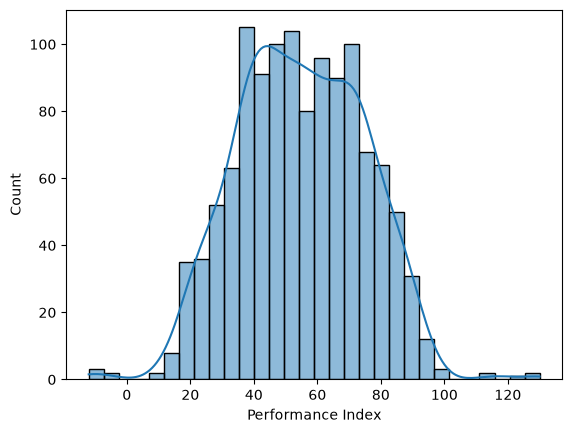

In [53]:
# code here
sns.histplot(df, x = "Performance Index", kde = True, bins = 30)
plt.show()

**Q2. Hours Studied와 Performance Index의 관계를 산점도로 시각화하세요.**

그리고 이 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

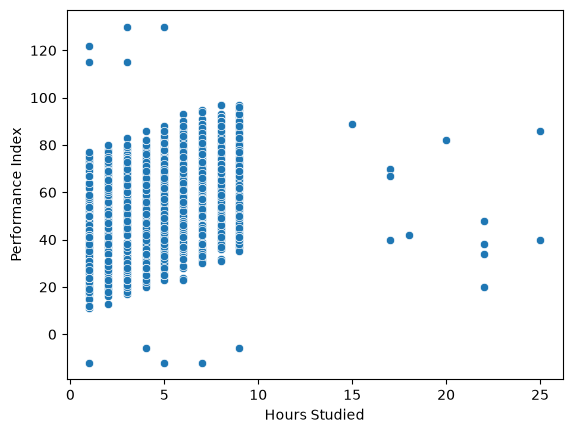

In [52]:
# code here
sns.scatterplot(df, x = "Hours Studied", y = "Performance Index")
plt.show()

**Q3. Hours Studied와 Weekly Study Hours를 산점도로 시각화하세요.**

그리고 이 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

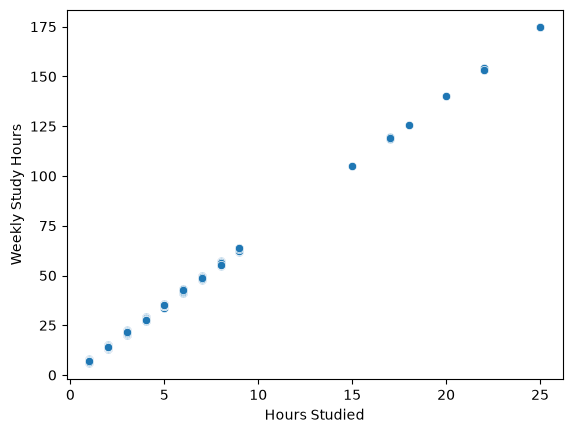

In [54]:
# code here
sns.scatterplot(df, x = "Hours Studied", y = "Weekly Study Hours")
plt.show()

**Q3. Extracurricular Activities 여부별 Performance Index를 박스플롯(box plot)으로 비교하세요.**

그리고 이 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

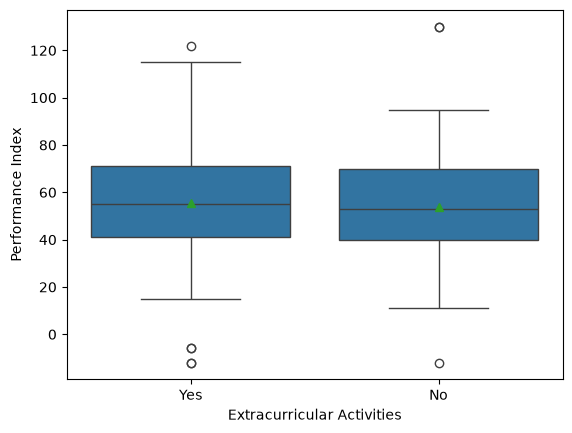

In [55]:
# code here
sns.boxplot(df, x = "Extracurricular Activities", y = "Performance Index", showmeans = True)
plt.show()

**Q5. 공부 시간의 이상치를 박스플롯으로 확인하세요.**

그리고 이 그래프로 알 수 있는 정보를 코드 아래 적어 주세요.

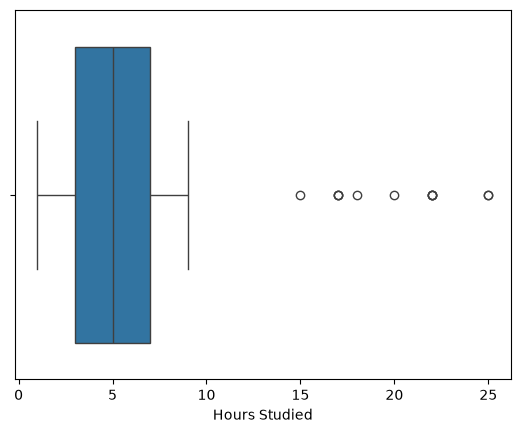

In [58]:
# code here
sns.boxplot(df, x = "Hours Studied", orient = 'h')
plt.show()


## **3. 데이터 전처리하기**

In [78]:
df = pd.read_csv("https://raw.githubusercontent.com/dukalee/datasets/refs/heads/main/student_performance.csv")
df.head()

,Hours Studied,Previous Scores,Extracurricular Activities,Sleep Hours,Sample Question Papers Practiced,Weekly Study Hours,Performance Index
0,6,92.0,Yes,9.0,4.0,42.2,86
1,1,54.0,No,7.0,7.0,6.9,28
2,7,45.0,Yes,6.0,6.0,49.3,38
3,5,70.0,Yes,4.0,6.0,35.6,55
4,1,47.0,Yes,5.0,0.0,6.9,18


### **3.1. 이상치 처리하기 1**

**Q1. 애초에 말도 안되는 데이터는 제거를 하자.**
- Performance Index는 음수가 되거나, 100을 초과할 수 없다.
- 공부 시간은 음수가 될 수 없다.

In [ ]:
# code here
# Performance Index가 음수나 100 초과하는 값
df[(df["Performance Index"] < 0) | (df["Performance Index"] > 100)].count()


Hours Studied                       10
Previous Scores                      9
Extracurricular Activities          10
Sleep Hours                         10
Sample Question Papers Practiced    10
Weekly Study Hours                  10
Performance Index                   10
dtype: int64

In [ ]:
# Performance Index가 음수나 100 초과하는 값 제거하기
invalid_perform = (df["Performance Index"] < 0) | (df["Performance Index"] > 100)
df = df[~invalid_perform]

### **3-2. 데이터 분리하기**

**Q1. Performance Index를 target으로 하여 train과 테스트 데이터를 분리합니다.**
- 비율 : 7(학습):3(테스트)
- random_state = 101

In [ ]:
# input: Performance Index만 제외한 모든 열들
X = df.drop("Performance Index", axis = 1) # axis = 0 행, axis = 1 열
    
# target
y = df["Performance Index"]

In [ ]:
# code here
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y)

### **3-3. 결측치 처리하기**

**Q1. train 데이터의 결측치 개수를 확인합니다.**

In [ ]:
# code here

**Q2. Previous Scores, Sleep Hours, Sample Question Papers Practiced의 결측치를 train 데이터의 중앙값(median)으로 대체하세요.**
- 이때 test 데이터에도 동일한(train 기준) 값을 사용하세요

In [ ]:
# code here

### **3-4. 이상치 처리하기 2**

**Q1. IQR을 통해 각 column에 outlier가 몇 개씩이나 있는지를 확인해보세요.**

In [ ]:
# code here

**Q2. 이상치가 존재하는 열들읠 행 정보들을 삭제합니다.**
- Hours Studied, Weekly Study Hours열에 존재하는 이상치 행들의 index를 추출하여, 삭제합니다.

In [ ]:
# code here

**Q3. 이상치 제거 검증을 위해 boxplot을 다시 한번 그려 봅시다.**

In [ ]:
# code here

### **3-5. Feature Encoding**

**Q. Extracurricular Activities 컬럼을 인코딩하세요.**

Binary (0 또는 1)인 상황이니, Label Enoder를 활용하여 인코딩합니다.

In [ ]:
# code here

## **4. 모델 학습 및 평가**

### **4-1. 모델 학습**

**Q1. Linear Regression 모델을 만들고, 학습시키세요.**

In [ ]:
# code here

### **4-2. 예측**

**Q1. 학습된 모델로 test 데이터에 대한 예측값을 구하세요.**

In [ ]:
# code here

### **4-3. 모델 평가**

**Q1. MSE, RMSE, R2 Score를 이용해 모델 성능을 평가하세요.**

In [ ]:
# code here